# Dataset Cleaning for Series Post

In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import zscore
from scipy.stats import iqr


series_post = pd.read_csv("../basketballPlayoffs/series_post.csv")
series_post.head()

,year,round,series,tmIDWinner,lgIDWinner,tmIDLoser,lgIDLoser,W,L
0,1,FR,A,CLE,WNBA,ORL,WNBA,2,1
1,1,FR,B,NYL,WNBA,WAS,WNBA,2,0
2,1,FR,C,LAS,WNBA,PHO,WNBA,2,0
3,1,FR,D,HOU,WNBA,SAC,WNBA,2,0
4,1,CF,E,HOU,WNBA,LAS,WNBA,2,0


# Check For Null Values

In [38]:
null = series_post.isnull().values.any()
nan = series_post.isna().values.any()

print(null)
print(nan)

# No Missing Values detected so no need of cleaning

False
False


# Dropping Unique Value Columns

In [39]:
for name in series_post:
    for col in series_post.columns:
        if len(series_post[col].unique()) == 1:
            series_post.drop(col, inplace=True, axis=1)
    print(f"Processed {name}: Remaining columns: {series_post.columns}")


Processed year: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='object')
Processed round: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='object')
Processed series: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='object')
Processed tmIDWinner: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='object')
Processed lgIDWinner: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='object')
Processed tmIDLoser: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='object')
Processed lgIDLoser: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='object')
Processed W: Remaining columns: Index(['year', 'round', 'series', 'tmIDWinner', 'tmIDLoser', 'W', 'L'], dtype='obj

# Dealing with Redundancy

In [40]:

row_count = series_post.shape[0]
series_post.drop_duplicates(inplace=True)
afterDups_count = series_post.shape[0]
rows_deleted = row_count - afterDups_count
print(f"Number of rows deleted: {rows_deleted}")


Number of rows deleted: 0


# Dealing With Outliers

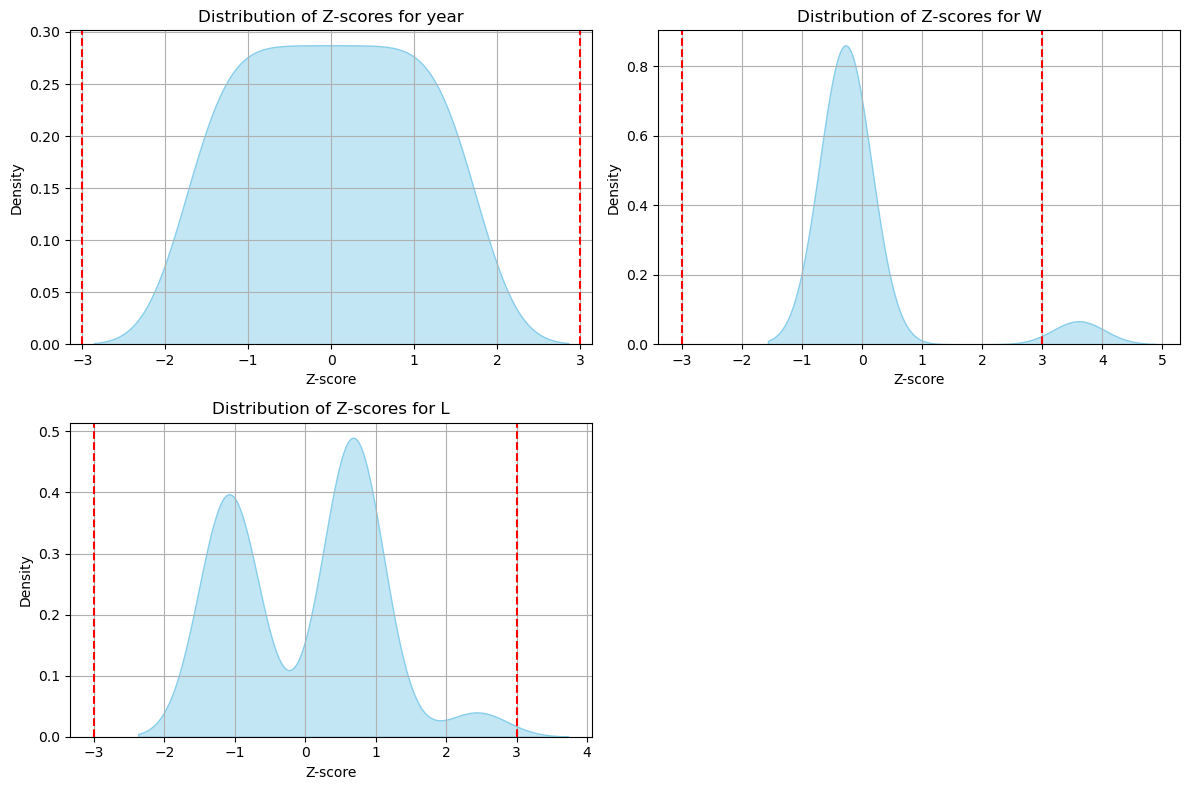

Number of outliers per column:
year    0
W       5
L       0
dtype: int64
Rows identified with any outliers: 5
Number of rows deleted: 0


In [41]:
numerical_cols = series_post.select_dtypes(['number'])

df = numerical_cols.apply(zscore)

exclude_rows = series_post['W'].notna()

num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))

axes = axes.flatten()
for i, column in enumerate(numerical_cols.columns):
    sns.kdeplot(df[column], fill=True, color='skyblue', alpha=0.5, ax=axes[i])
    axes[i].set_title(f'Distribution of Z-scores for {column}')
    axes[i].set_xlabel('Z-score')
    axes[i].set_ylabel('Density')
    axes[i].grid(True)
    axes[i].axvline(x=3, color='red', linestyle='--')
    axes[i].axvline(x=-3, color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

threshold = 3
outlier_mask = (df.abs() > threshold)
outliers_per_column = outlier_mask.sum()
print("Number of outliers per column:")
print(outliers_per_column)

rows_with_outliers = outlier_mask.any(axis=1)
print("Rows identified with any outliers:", rows_with_outliers.sum())

df_no_outliers = df[~(rows_with_outliers & ~exclude_rows)]

num_rows_deleted = df.shape[0] - df_no_outliers.shape[0]
print(f"Number of rows deleted: {num_rows_deleted}")


# IQR

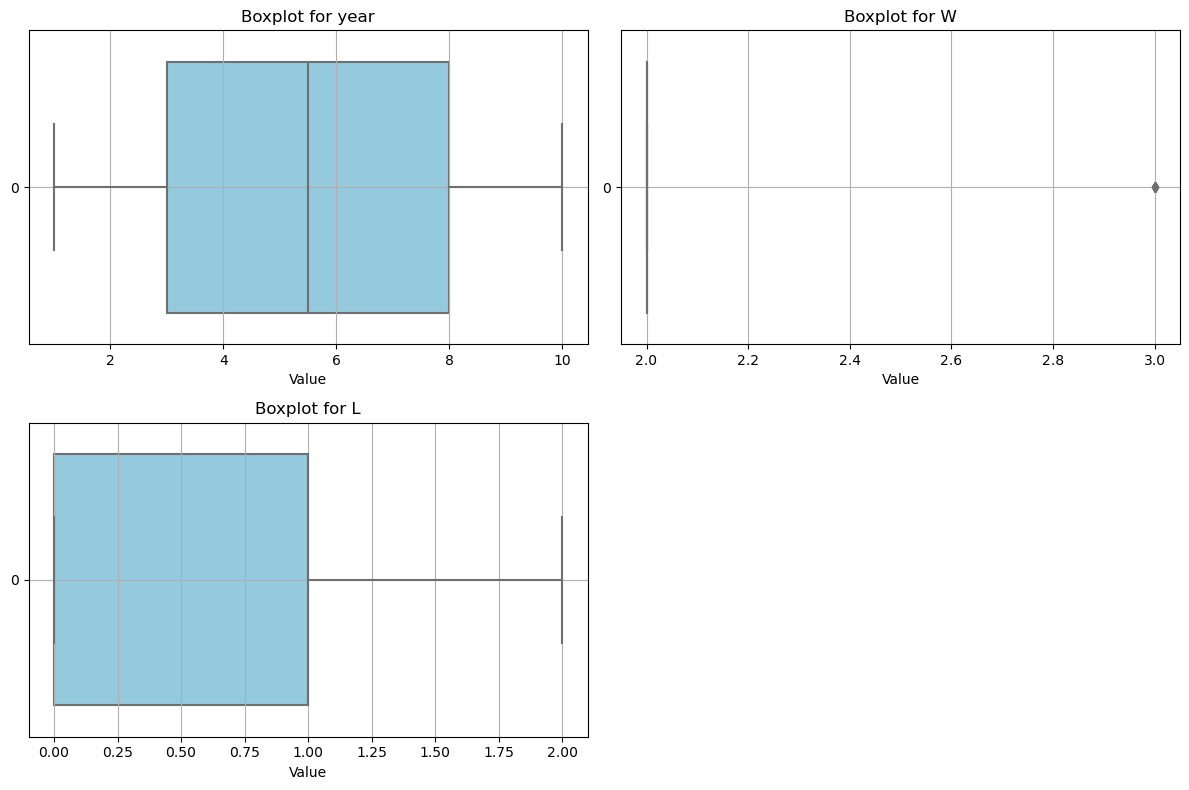

Number of rows deleted: 0


In [42]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import iqr

numerical_cols = series_post.select_dtypes(['number'])

df = numerical_cols.copy()

exclude_rows = series_post['W'].notna()

num_columns = 2
num_rows = (len(numerical_cols.columns) + 1) // num_columns  
fig, axes = plt.subplots(num_rows, num_columns, figsize=(12, num_rows * 4))

axes = axes.flatten()
for i, column in enumerate(numerical_cols.columns):
    sns.boxplot(data=series_post[column], ax=axes[i], color='skyblue', orient='h')
    axes[i].set_title(f'Boxplot for {column}')
    axes[i].set_xlabel('Value')
    axes[i].grid(True)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

lower_bounds = {}
upper_bounds = {}
outliers_iqr = pd.DataFrame(False, index=series_post.index, columns=numerical_cols.columns)

for column in numerical_cols.columns:
    Q1 = series_post[column].quantile(0.25)
    Q3 = series_post[column].quantile(0.75)
    column_iqr = iqr(series_post[column])
    lower_bound = Q1 - 1.5 * column_iqr
    upper_bound = Q3 + 1.5 * column_iqr
    lower_bounds[column] = lower_bound
    upper_bounds[column] = upper_bound
    outliers_iqr[column] = (series_post[column] < lower_bound) | (series_post[column] > upper_bound)

outlier_indices_iqr = outliers_iqr.any(axis=1)
rows_with_outliers_iqr = outlier_indices_iqr & ~exclude_rows

df_no_outliers = df[~rows_with_outliers_iqr]

num_rows_deleted = df.shape[0] - df_no_outliers.shape[0]
print(f"Number of rows deleted: {num_rows_deleted}")


# Create Clean CSV

In [43]:
series_post.to_csv('../cleaned_datasets/series_post_cleaned.csv', index=False)